# Correction du module Algo

Voici quelques notes, courbes et explications sur ce que nous avons vu dans le module Algo. Les exemples de code reposent tous sur le module `sorting.py` qui accompagne ce _notebook_.

Il existe plusieurs possibilités pour importer des objets python depuis un autre fichier. Les méthodes ici fonctionnent si vous avez installé un paquet via `pip` ou `conda` ou tout autre gestionnaire de paquet, ou si votre fichier contenant les objets à importer est au même niveau que ce notebook dans les dossiers.

On importe le module. Les fonctions du module vivent alors dans leur propre espace de noms (_namespace_ en anglais). L'utilisation des fonctions demande à ce qu'on les préfixe par le nom du module. Par exemple :

`import sorting`

`sorting.bubble_sort(tab)` # pour utiliser la fonction bubble_sort du paquet/module sorting

Autres types d'imports possibles. L'on peut importer un paquet/module et le renommer pour simplifier son usage.  

`import sorting as srt`


`srt.bubble_sort(tab)`

Si l'on a besoin que de certains objets du paquet/module, l'on peut importer uniquement ces objets de façon spécifique.
On intègre la fonction à l'espace de nom général.
Plus besoin de la préfixer.

Pour importer une fonction:  

`from sorting import bubble_sort`

`bubble_sort(tab)`

pour importer plusieurs objet

`from sorting import bubble_sort, insertion_sort`

`bubble_sort(tab)`

ou

`from sorting import (`  
&nbsp;&nbsp;&nbsp;&nbsp;`bubble_sort,`  
&nbsp;&nbsp;&nbsp;&nbsp;`insertion_sort`  
`)`

`bubble_sort(tab)`

On peut cumuler plusieurs techniques précisées ci-dessus

`from sorting import bubble_sort as bbb`

`bbb(tab)`

On intègre toutes les fonctions du module à l'espace de nom général. **Cette notation est à éviter**, **elle devrait même être interdite !!**. On ne sait pas ce qu'on importe. Si on fait ça sur plusieurs modules et que certains ont des fonctions avec des noms identiques, on écrase les définitions de ces fonctions par d'autres. Mauvaises surprises garanties !

**On le voit UNE FOIS pour ne plus jamais le voir**  

`from sorting import *`

`bubble_sort(tab)`

## Itération 1 - Les tris classiques

In [18]:
import sorting

### Le tri à bulles

In [19]:
# Génération d'un tableau désordonné
tab = sorting.generate_random_array()
print("Avant tri :", tab)

# Tri et affichage du tableau trié
sorting.bubble_sort(tab)
print("Après tri :", tab)

# On vérifie ici que le tableau est bien trié grâce à une assertion.
# En programmant, soyez paranoïaque !
assert(tab == sorted(tab))

Avant tri : [14, 19, 6, 10, 4, 2, 17, 11, 13, 15, 1, 9, 12, 16, 7, 20, 18, 8, 0, 3, 5]
Après tri : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


> **Note sur les assertions**
>
> `assert(condition)` est une fonction qui vérifie si la condition qu'on lui donne comme paramètre est vraie. Si la condition est fausse, une exception est levée et le programme s'arrête. Sinon, le programme continue normalement. 
>
> Les assertions sont beaucoup utilisées pendant la phase de développement d'un programme, pour s'assurer que le code marche comme on le souhaite. Elles sont en général enlevées en production pour optimiser le temps d'exécution du programme (vérifier une assertion prend du temps de calcul).

Le tri à bulles utilise deux boucles itératives imbriquées. Ce ne sont pas des boucles conditionnelles et il n'y a aucune condition permettant de sortir d'une boucle (il n'y a pas d'instruction `break`). Du coup, le nombre d'opérations effectuées sera toujours le même, quel que soit l'état du tableau en entrée. Les complexités dans le meilleur cas, dans le pire cas et dans le cas moyen sont donc identiques. Elles sont en $O(n^2)$.

Ce résultat s'obtient en comptant le nombre total de comparaisons (le cœur de notre fonction de tri). Considérons que le tableau en entrée est de taille $n$. À la première itération de la boucle principale, $i$ vaut $n - 1$. La seconde boucle va faire varier $j$ de $0$ à $n - 2$, ce qui représente $n - 1$ itérations et donc $n - 1$ comparaisons. À la seconde itération de la boucle principale, $i$ vaut $n - 2$, $j$ va varier de $0$ à $n - 3$, soit $n - 2$ comparaisons. Il en va de même jusqu'à ce que le nombre de comparaisons arrivent à 1 pour la dernière itération de la boucle principale.

Pour avoir le nombre total de comparaisons, il faut faire la somme de toutes les itérations. L'astuce consiste ensuite à voir qu'il s'agit de [la somme des entiers naturels](https://fr.wikipedia.org/wiki/Somme_(arithm%C3%A9tique)#Somme_des_premiers_entiers) de $1$ à $n - 1$ : $$1 + 2 + ... + (n - 2) + (n - 1) = \frac{n(n-1)}2 = \frac{1}{2}(n^2 - n)$$

Quand on recherche la complexité d'un algorithme, on cherche l'ordre de grandeur du nombre d'opérations (et donc, du temps de calcul). On est pas à une constante près. Le terme $\frac{1}{2}$ disparaît. De plus, $n^2$ va grandir beaucoup plus vite que $n$. On peut donc négliger $n$. Ce qui nous amène donc à la complexité $O(n^2)$.

Concrètement, cela signifie que pour un tableau de taille 10, il faudrait un ordre de grandeur de 100 comparaisons pour le trier. Pour un tableau de taille 100, l'ordre de grandeur passe à 10 000 comparaisons. Donc, quand les données grandissent d'un facteur 10, le temps d'exécution grandit d'un facteur 100 !

> **Liste des complexités en temps classiques**
>
>  - $O(1)$, complexité constante
>  - $O(\log n)$, complexité logarithmique
>  - $O(n)$, complexité linéaire
>  - $O(n \log n)$, complexité quasi-linéaire
>  - $O(n^2)$, complexité quadratique
>  - $O(n^3)$, complexité cubique
>  - $O(2^n)$, complexité exponentielle
>  - $O(n!)$, complexité factorielle
>
> Cette liste est ordonnée. Servez-vous-en pour savoir quel terme est négligeable par rapport à un autre lors du calcul de la complexité d'un algorithme.

### Tri par insertion

In [20]:
# Génération d'un tableau désordonné
tab = sorting.generate_random_array()
print("Avant tri :", tab)

# Tri et affichage du tableau trié
sorting.insertion_sort(tab)
print("Après tri :", tab)
 
assert(tab == sorted(tab))  # Paranoïa quand tu nous tiens !

Avant tri : [20, 14, 12, 11, 6, 1, 10, 7, 0, 2, 3, 19, 17, 4, 5, 18, 16, 15, 8, 13, 9]
Après tri : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


Le tri par insertion utilise une boucle conditionnelle à l'intérieur de la boucle principale. Une boucle conditionnelle s'arrête lorsque sa condition est fausse. On peut même ne pas rentrer du tout dans la boucle si la condition est fausse dès le départ.

Cette boucle conditionnelle complique un peu le calcul des complexités par rapport au cas du tri à bulles. Il faut faire la distinction pour chacun des cas : le meilleur cas, le pire des cas et le cas moyen.

#### Meilleur des cas

Le meilleur des cas est celui où l'on fait le moins d'opérations. Pour le tri par insertion, c'est le cas où la seconde boucle n'est jamais exécutée. Cela signifie qu'à chaque itération de la boule principale, il faut que la condition `tab[j - 1] > x` soit fausse. Cette condition s'écrit encore `tab[i - 1] > tab[i]` en remplaçant `x` et `j` par les valeurs qu'on vient juste de leur donner. Dans le cas où le tableau est déjà trié, la condition précédente est toujours fausse, quelle que soit la valeur de `i`. Le meilleur des cas, c'est donc quand le tableau est déjà trié.

Dans ce cas-là, vu que la condition de la seconde boucle est toujours fausse, on ne rentre jamais dedans. Donc, il n'y a qu'une comparaison qui est faite par itération de la boucle principale. La boucle principale est répétée $n - 1$ fois. La complexité dans le meilleur des cas est donc linéaire : $O(n)$.

#### Pire des cas

Le pire des cas est celui où le tableau est trié en sens inverse. La boucle conditionnelle sur la variable `j` est alors exécutée jusqu'à ce que `j` atteigne 0 à chaque fois. À la première itération de la boucle principale, il faudra faire 1 comparaison. À la seconde, 2 comparaisons. Ainsi de suite jusqu'à la dernière où il faudra faire $n - 1$ comparaisons. Ça vous rappelle quelque chose ? C'est le même calcul que pour le tri à bulles : la complexité est quadratique, en $O(n^2)$.

#### Cas moyen

Le calcul du cas moyen pose problème. On ne peut pas dénombrer comme avant le nombre d'opérations à chaque itération de la boucle principale. Cela dépend de la permutation des éléments dans les données en entrée.

Il existe alors une manière théorique de calculer la complexité, en associant une loi de probabilité sur l'ensemble des permutations du tableau. On tomberait alors sur un nombre moyen d'opérations équivalent à $\frac{n^2}{4}$.

Si vous n'avez pas compris un mot sur deux de la phrase précédente, rassurez-vous, vous n'êtes pas seuls ! Le calcul théorique est compliqué à réaliser, c'est pourquoi on va procéder autrement. Nous allons estimer la complexité expérimentalement !

In [21]:
import numpy
import timeit

N_ITERATIONS = 1000

tailles = numpy.array([1, 25, 50, 75, 100, 125, 150])
temps = []

for taille in tailles:
    # timeit va exécuter plusieurs fois le `stmt` dans son propre environnement
    # et va renvoyer le temps pris. Son environnement est vide par défaut. C'est
    # pourquoi, grâce au `setup` exécuté une unique fois, le module sorting est 
    # importé dans l'environnement timeit pour être utilisé à chaque itération.
    temps_pour_n_iterations = timeit.timeit(
        setup="import sorting",
        stmt=f"sorting.insertion_sort(sorting.generate_random_array(N={taille}))",
        number=N_ITERATIONS
    )
    # timeit exécute plusieurs fois le code demandé et renvoie le temps global.
    # On divise donc pour avoir le temps d'une exécution de l'algorithme.
    temps.append(temps_pour_n_iterations / N_ITERATIONS)

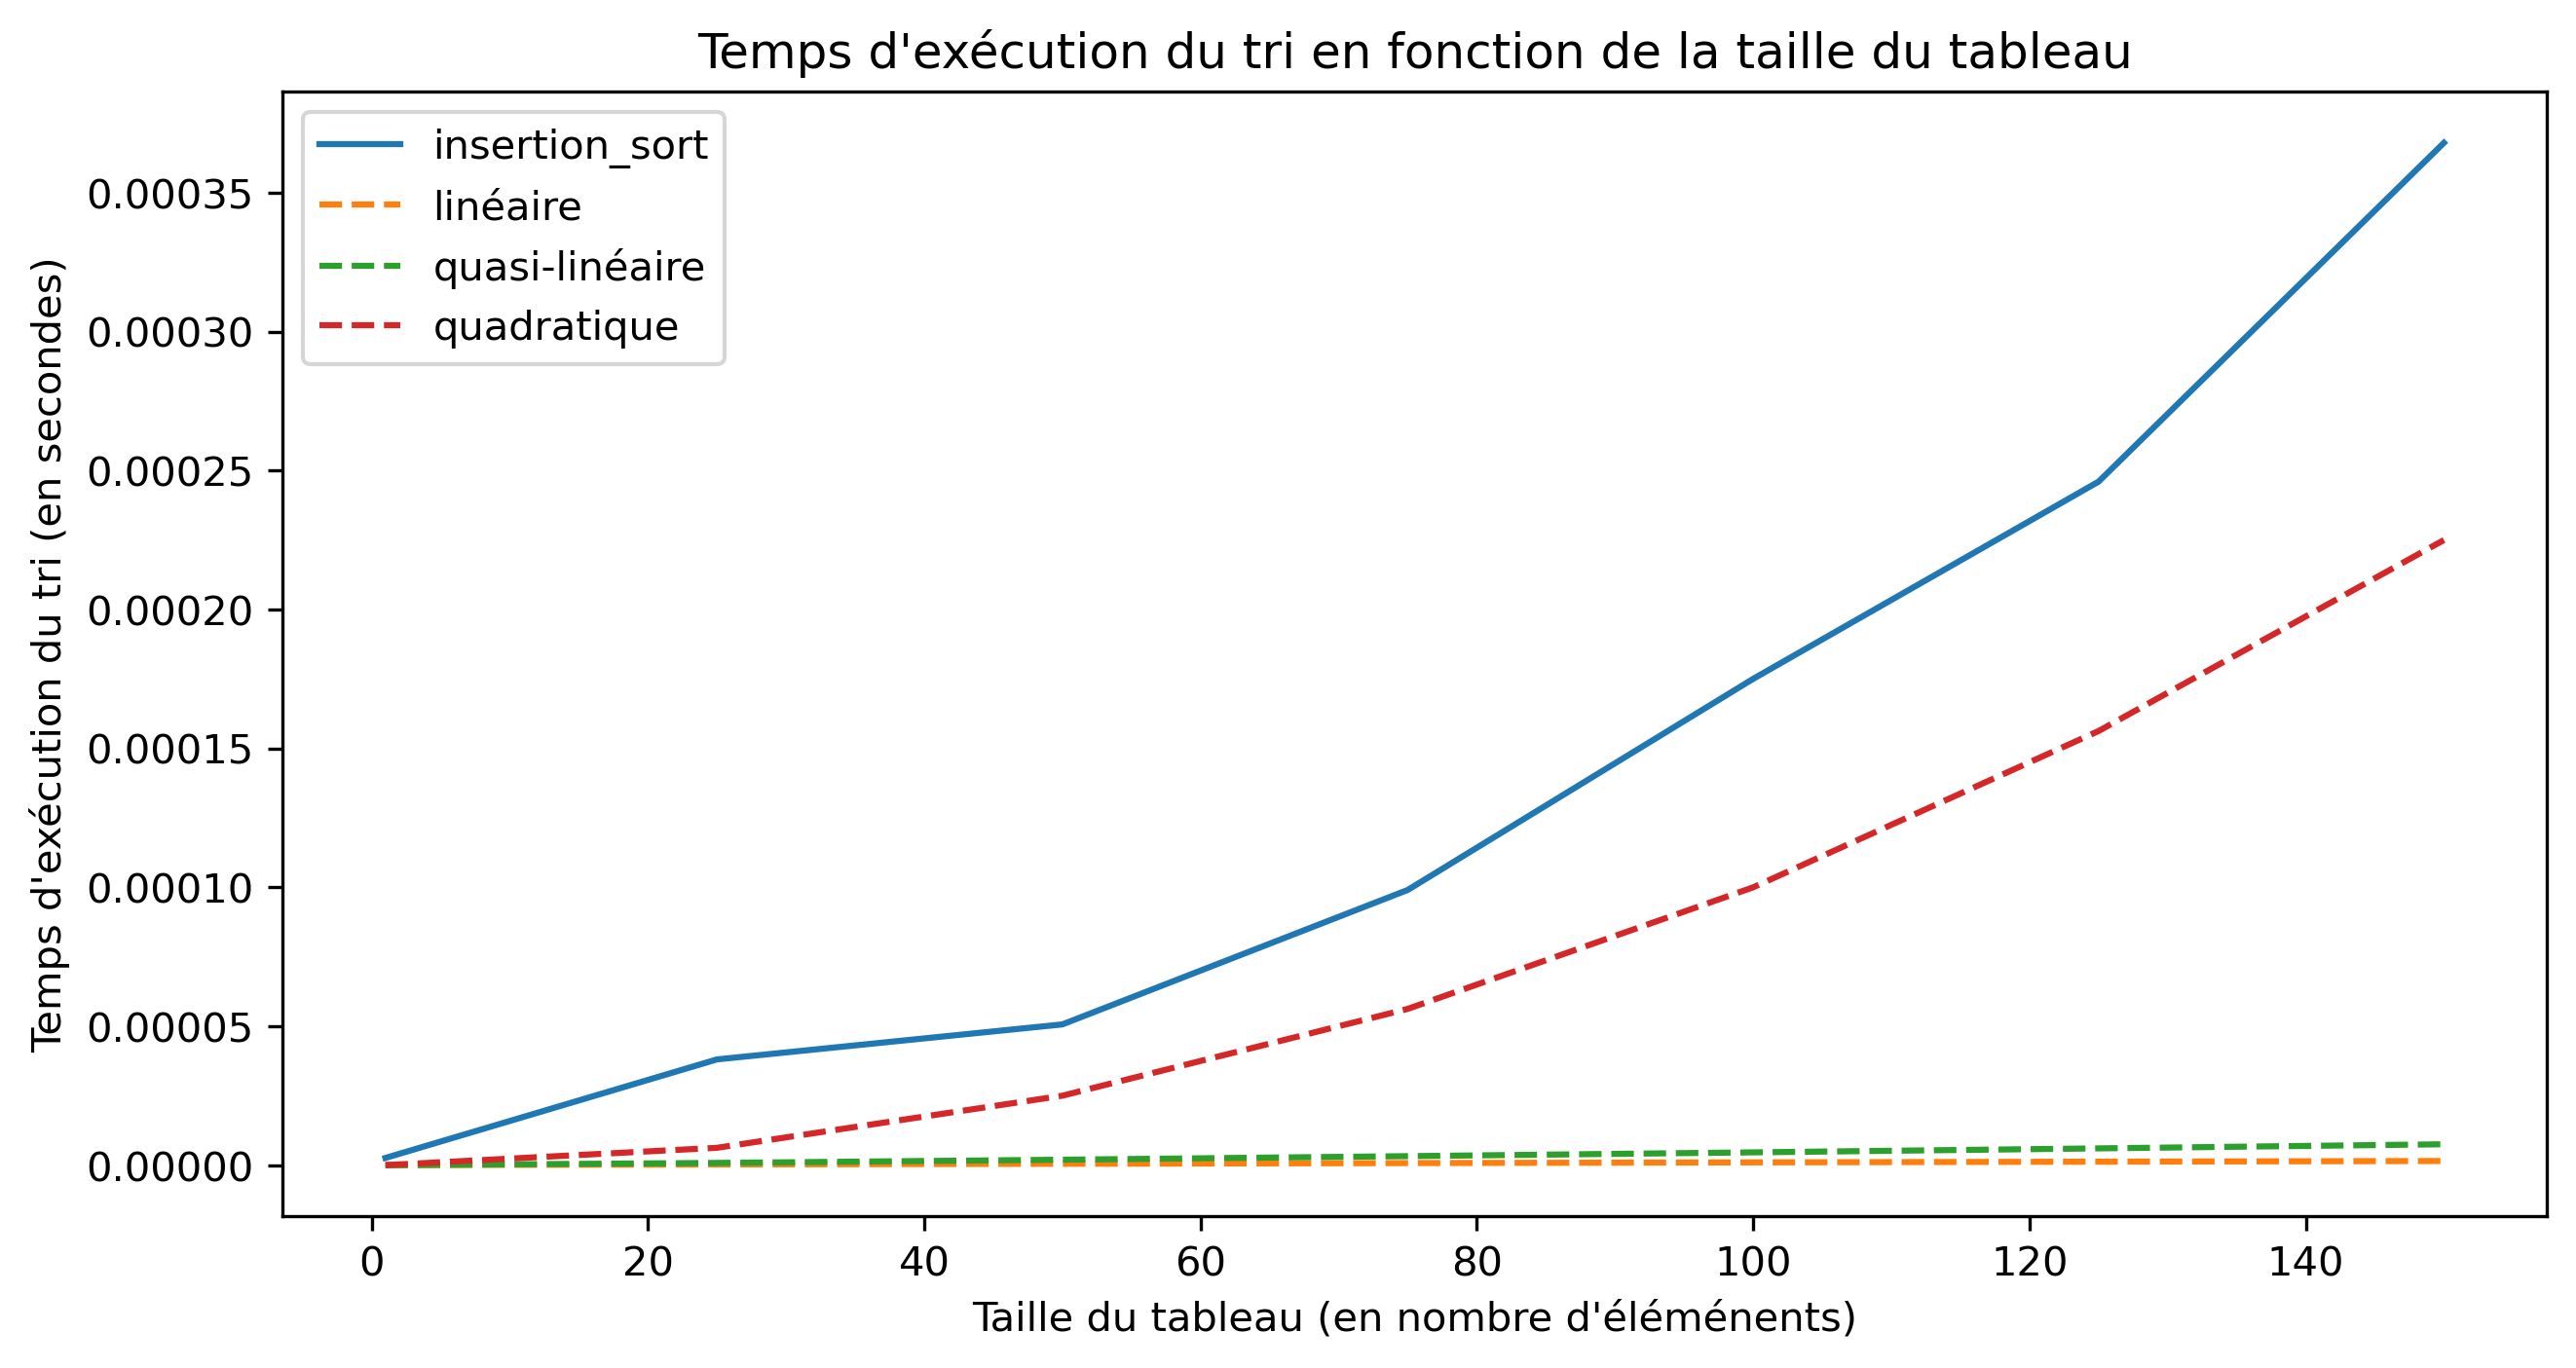

In [30]:
import matplotlib.pyplot as plt

# À changer en fonction de la machine qui exécute le code
NORMALISATION_PROCESSEUR = 0.00000001

# Affichage de la courbe, avec des complexités classiques pour comparaison
plt.figure(figsize=(10, 5), dpi=300.0)
plt.plot(tailles, temps, label='insertion_sort')
plt.plot(tailles, NORMALISATION_PROCESSEUR * tailles,  linestyle='--', label='linéaire')
plt.plot(tailles, NORMALISATION_PROCESSEUR * tailles * numpy.log(tailles), linestyle='--', label='quasi-linéaire')
plt.plot(tailles, NORMALISATION_PROCESSEUR * tailles ** 2, linestyle='--', label='quadratique')
plt.xlabel("Taille du tableau (en nombre d'éléménents)")
plt.ylabel("Temps d'exécution du tri (en secondes)")
plt.title("Temps d'exécution du tri en fonction de la taille du tableau")
plt.legend();

Comme le montre la figure, le temps d'exécution du tri par insertion est très proche de la courbe quadratique. On pourrait ajouter une constante pour _fiter_ la courbe. Mais ce n'est pas ce qui nous intéresse ici. Nous voulons un ordre de grandeur de la complexité. Nous nous contenterons de constater qu'elle est quadratique, en $O(n^2)$, comme la théorie nous l'indiquait. Nous avons retrouvé ce résultat expérimentalement.

> C'est quoi la constante `NORMALISATION_PROCESSEUR` dans le code précédent ?
>
> Pour les courbes de complexité, nous avons calculé l'ordre de grandeur du nombre d'instructions à exécuter. Or, pour notre tri par insertion, nous avons mesuré le temps d'exécution. Afin de comparer ce qui est comparable, il faut multiplier le nombre d'instructions par la durée moyenne d'une instruction. Cette durée dépend de la puissance du processeur qui exécute le code. À vous de trouver la bonne constante pour que les courbes de complexité soient « comparables » à la courbe de la fonction de tri. Et rappelez-vous, nous cherchons un ordre de grandeur, nous ne sommes pas à une constante près.
>
> Nous aurions aussi pu compter le nombre d'instructions exécutées grâce à la méthode magique `%lprun`. Ainsi, nous aurions tout de suite pu comparer nos courbes, sans avoir besoin de la constante `NORMALISATION_PROCESSEUR`. Mais ça aurait été moins facilement automatisable...

### Tri par sélection

In [23]:
# Génération d'un tableau désordonné
tab = sorting.generate_random_array()
print("Avant tri :", tab)

# Tri et affichage du tableau trié
sorting.selection_sort(tab)
print("Après tri :", tab)
 
assert(tab == sorted(tab))  # Paranoïa quand tu nous tiens !

Avant tri : [12, 11, 10, 16, 20, 0, 5, 7, 8, 14, 13, 15, 1, 18, 2, 4, 19, 9, 6, 3, 17]
Après tri : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


Le calcul de la complexité pour le tri par sélection est similaire au calcul pour le tri à bulles. En effet, nous sommes dans la même configuration avec deux boucles itératives imbriquées. Il n'y a pas de conditions qui nous permet de quitter plus rapidement les boucles dans un cas ou l'autre. Les complexités dans le meilleur cas, dans le pire cas et dans le cas moyen sont donc les mêmes.

De plus, le comptage d'opérations est très similaire. Pour la première itération de la boucle principale, la boucle secondaire va s'exécuter $n - 1$ fois. Puis $n - 2$ fois pour la seconde itération. Et ainsi de suite jusqu'à $1$ fois sur la dernière itération. Encore une fois, nous avons à faire à la somme des entiers naturels. La complexité du tri par sélection est donc quadratique, en $O(n^2)$.

## Itération 2 - Les tris récursifs

### Le tri fusion

In [7]:
# Génération d'un tableau désordonné
tab = sorting.generate_random_array()
print("Avant tri :", tab)

# Tri et affichage du tableau trié
sorting.merge_sort(tab)
print("Après tri :", tab)
 
#assert(tab == sorted(tab))  # Paranoïa quand tu nous tiens !

Avant tri : [14, 13, 11, 15, 3, 7, 16, 6, 19, 9, 5, 2, 10, 4, 1, 8, 18, 12, 20, 17, 0]
Après tri : [14, 13, 11, 15, 3, 7, 16, 6, 19, 9, 5, 2, 10, 4, 1, 8, 18, 12, 20, 17, 0]


Pour le calcul de la complexité, observons le schéma suivant :

```
                           n = 8                                                                    ASCII <3
                      _ _ _ _ _ _ _ _
            ^        |_|_|_|_|_|_|_|_| <-----+
            |                                |    / min 4 comparaisons         max
3 divisions |         /             \        | 1x |                    <=> 1 x (n - 1) <=> O(n)
            |     _ _ _ _         _ _ _ _    |    \ max 7 comparaisons     comparaisons
    <=>     |    |_|_|_|_|       |_|_|_|_| --+ <--+
            |                                     |    / min 2 comparaisons          max
  log2(8)   |     /     \         /     \         | 2x |                    <=> 2 x (n / 2 - 1) <=> O(n)
            |   _ _     _ _     _ _     _ _       |    \ max 3 comparaisons      comparaisons
    <=>     |  |_|_|   |_|_|   |_|_|   |_|_| -----+ <--+
            |                                          |    / min 1 comparaison          max
  log2(n)   |   / \     / \     / \     / \            | 4x |                   <=> 4 x (n / 4 - 1) <=> O(n)
            |  _   _   _   _   _   _   _   _           |    \ max 1 comparaison      comparaisons
            v |_| |_| |_| |_| |_| |_| |_| |_| ---------+
```

Ce schéma a pour objectif de vous faire comprendre la complexité du tri fusion. Il ne s'agit pas du calcul formel, que vous pourrez facilement retrouver quelque part sur les internets.

Le tableau est divisé en deux récursivement. Combien y aura-t-il de divisions successives ? Un nombre équivalent à la puissance de 2 contenue dans $n$, la taille de notre tableau.

> Si $n$ n'est pas une puissance de 2, ça marchera quand même, toujours pour la même raison : on cherche un ordre de grandeur du nombre d'instructions, pas le nombre exact d'instructions à exécuter. Et on peut toujours considérer que notre taille sera située entre deux puissances de $n$. Mathématiquement, il existe toujours $p$ tel que $2^p < n \leq 2^{p + 1}$.

Pour fusionner deux sous-tableaux triés de taille $\frac{n}{2}$ et retrouver un tableau trié de taille $n$, il faut entre $\frac{n}{2}$ et $n - 1$ comparaisons :

 - Le nombre minimal de comparaisons est obtenu quand les valeurs du premier sous-tableau sont toutes inférieures à la plus petite valeur du second sous-tableau. Il faut faire une comparaison entre tous les éléments du premier sous-tableau et la première valeur du second sous-tableau. Ensuite, tous les éléments du second sous-tableau sont ajoutés, sans comparaison nécessaire.
 - Le nombre maximal de comparaisons est obtenu quand les deux sous-tableaux sont « emmêlés » et qu'il faut prendre successivement une valeur dans le premier sous-tableau, puis le second sous-tableau, puis à nouveau le premier, etc.
 
Dans tous les cas, pour chaque étage de décomposition du problème, il est nécessaire de faire environ $n$ comparaisons. Le sous-problème, qui consiste à fusionner les sous-tableaux pour « remonter » d'un cran dans la récursion a une complexité linéaire, en $O(n)$.

Au final, comme il y a $\log_2(n)$ étages, et que la complexité de résolution d'un étage est linéaire, la complexité globale de notre problème est $O(n \log n)$.

> Pourquoi la complexité ne s'écrit pas $O(n \log_2 n)$ ?
>
> Pour le logarithme, le passage d'une base à l'autre revient à [multiplier par une constante](https://fr.wikipedia.org/wiki/Logarithme#Changement_de_base). Et comme on est pas à une constante près, on ne s'embête pas à préciser la base dans la notation de la complexité.

### Le tri rapide

In [31]:
# Génération d'un tableau désordonné
tab = sorting.generate_random_array()
print("Avant tri :", tab)

# Tri et affichage du tableau trié
sorting.quick_sort(tab,0,len(tab)-1)
print("Après tri :", tab)
 
#assert(tab == sorted(tab))  # Paranoïa quand tu nous tiens !

Avant tri : [11, 5, 0, 2, 18, 14, 3, 12, 4, 8, 15, 13, 19, 16, 20, 1, 9, 6, 10, 7, 17]
Après tri : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


Vous vous souvenez du schéma précédent pour le calcul de la complexité du tri fusion ? C'est un peu la même idée ici : on va diviser en deux notre tableau à chaque fois. Sauf que ce n'est pas en deux parties égales. On utilise un pivot pour la division en deux. Ce pivot est pris comme le premier élément du sous-tableau qu'on est en train de trier. Le choix du premier élément simplifie l'implémentation, mais ça revient à prendre un nombre au hasard parmi tous les nombres du sous-tableau. Le nombre d'éléments plus petits que le pivot est très certainement différent du nombre d'éléments plus grands que le pivot.

La conséquence, c'est que comme il y a un sous-tableau plus grand, il faudra plus d'étages à nos récursions avant d'arriver au cas de base où il ne reste qu'un élément dans les sous-tableaux. Cependant, l'ordre de grandeur du nombre d'étages reste en $O(\log n)$ dans le cas moyen.

Il y a cependant un cas particulièrement défavorable. Si le tableau est déjà trié (dans le bon ordre ou dans l'ordre inverse, c'est pareil), le pivot sera toujours le plus petit (ou le plus grand) élément du sous-tableau. Ça veut dire qu'un tableau de taille $n$ sera divisée en deux sous-tableaux de taille $1$ et $n-1$. Il faudrait donc $n$ étages à notre récursion pour terminer.

Le cas optimal est le cas où l'on utilise la médiane comme pivot d'un tableau. On divise alors le tableau en deux sous-tableaux de même taille. On va ainsi limiter le nombre d'étages de la récursion au strict minimum. Cependant, identifier la médiane d'un tableau prend du temps et ajoute de la complexité à notre algorithme. Certains ont alors développé des méthodes d'[estimation de la médiane](https://fr.wikipedia.org/wiki/M%C3%A9diane_des_m%C3%A9dianes). Mais même avec une médiane estimée, les implémentations du tri rapide utilisant la médiane sont en pratique plus lents que les implémentations utilisant un pivot aléatoire.

La séparation d'un tableau en deux sous-tableaux demande à parcourir une fois le tableau, la complexité est donc linéaire, en $O(n)$, pour l'opération de partition.

Au final, nous avons dans le pire des cas une complexité quadratique, en $O(n^2)$. Contrairement au tri par insertion qui est plus rapide quand le tableau est déjà trié, le tri rapide est plus lent quand le tableau est déjà trié. Dans le cas moyen, la complexité est en $O(n \log n)$.

> **Petite astuce**
>
> Il est possible d'échanger l'élément central d'un sous-tableau avec le premier élément du sous-tableau avant de se servir du nouveau premier élément comme pivot. Cette stratégie permet, dans le cas où le tableau est déjà trié, de ne pas se retrouver dans le pire des cas, mais au contraire d'être dans le meilleur des cas : on utilise la médiane comme pivot !

### Comparaison de tous les tris

Pour une comparaison juste et équitable des algorithmes de tri, il faut donner les mêmes tableaux à chacune des fonctions de tri. Cependant, il faut être prudent avec notre mesure de temps. `timeit` répète plusieurs fois le même code pour obtenir un temps moyen. Or, si on trie plusieurs fois exactement le même tableau, à partir de la seconde répétition du tri, le tableau en entrée est déjà trié, ce qui va largement aider certains algorithmes (tri par insertion) et en pénaliser d'autres (tri rapide). Il faut donc veiller à faire le tri sur un tableau non trié à chaque fois. Le plus simple est donc de faire une copie du tableau à chaque fois et de trier la copie. C'est pourquoi on utilise la fonction `list()` dans la suite. Elle crée une copie du tableau.

In [32]:
N_ITERATIONS = 100

tailles = numpy.array([1, 100, 200, 300, 400, 500])
bubble = []
insertion = []
selection = []
merge = []
quick = []

for taille in tailles:
    tab = sorting.generate_random_array(N=taille)
    # Cette fois-ci, on donne tout l'environnement à `timeit` grâce au paramètre `globals` pour 
    # qu'il ait connaissance du tableau qui doit être le même pour tous les tris.
    bubble.append(
        timeit.timeit(globals=globals(), stmt="sorting.bubble_sort(list(tab))", number=N_ITERATIONS) / N_ITERATIONS
    )
    insertion.append(
        timeit.timeit(globals=globals(), stmt="sorting.insertion_sort(list(tab))", number=N_ITERATIONS) / N_ITERATIONS

    )
    selection.append(
        timeit.timeit(globals=globals(), stmt="sorting.selection_sort(list(tab))", number=N_ITERATIONS) / N_ITERATIONS

    )
    merge.append(
        timeit.timeit(globals=globals(), stmt="sorting.merge_sort(list(tab))", number=N_ITERATIONS) / N_ITERATIONS

    )
    quick.append(
        timeit.timeit(globals=globals(), stmt="sorting.quick_sort(list(tab))", number=N_ITERATIONS) / N_ITERATIONS

    )

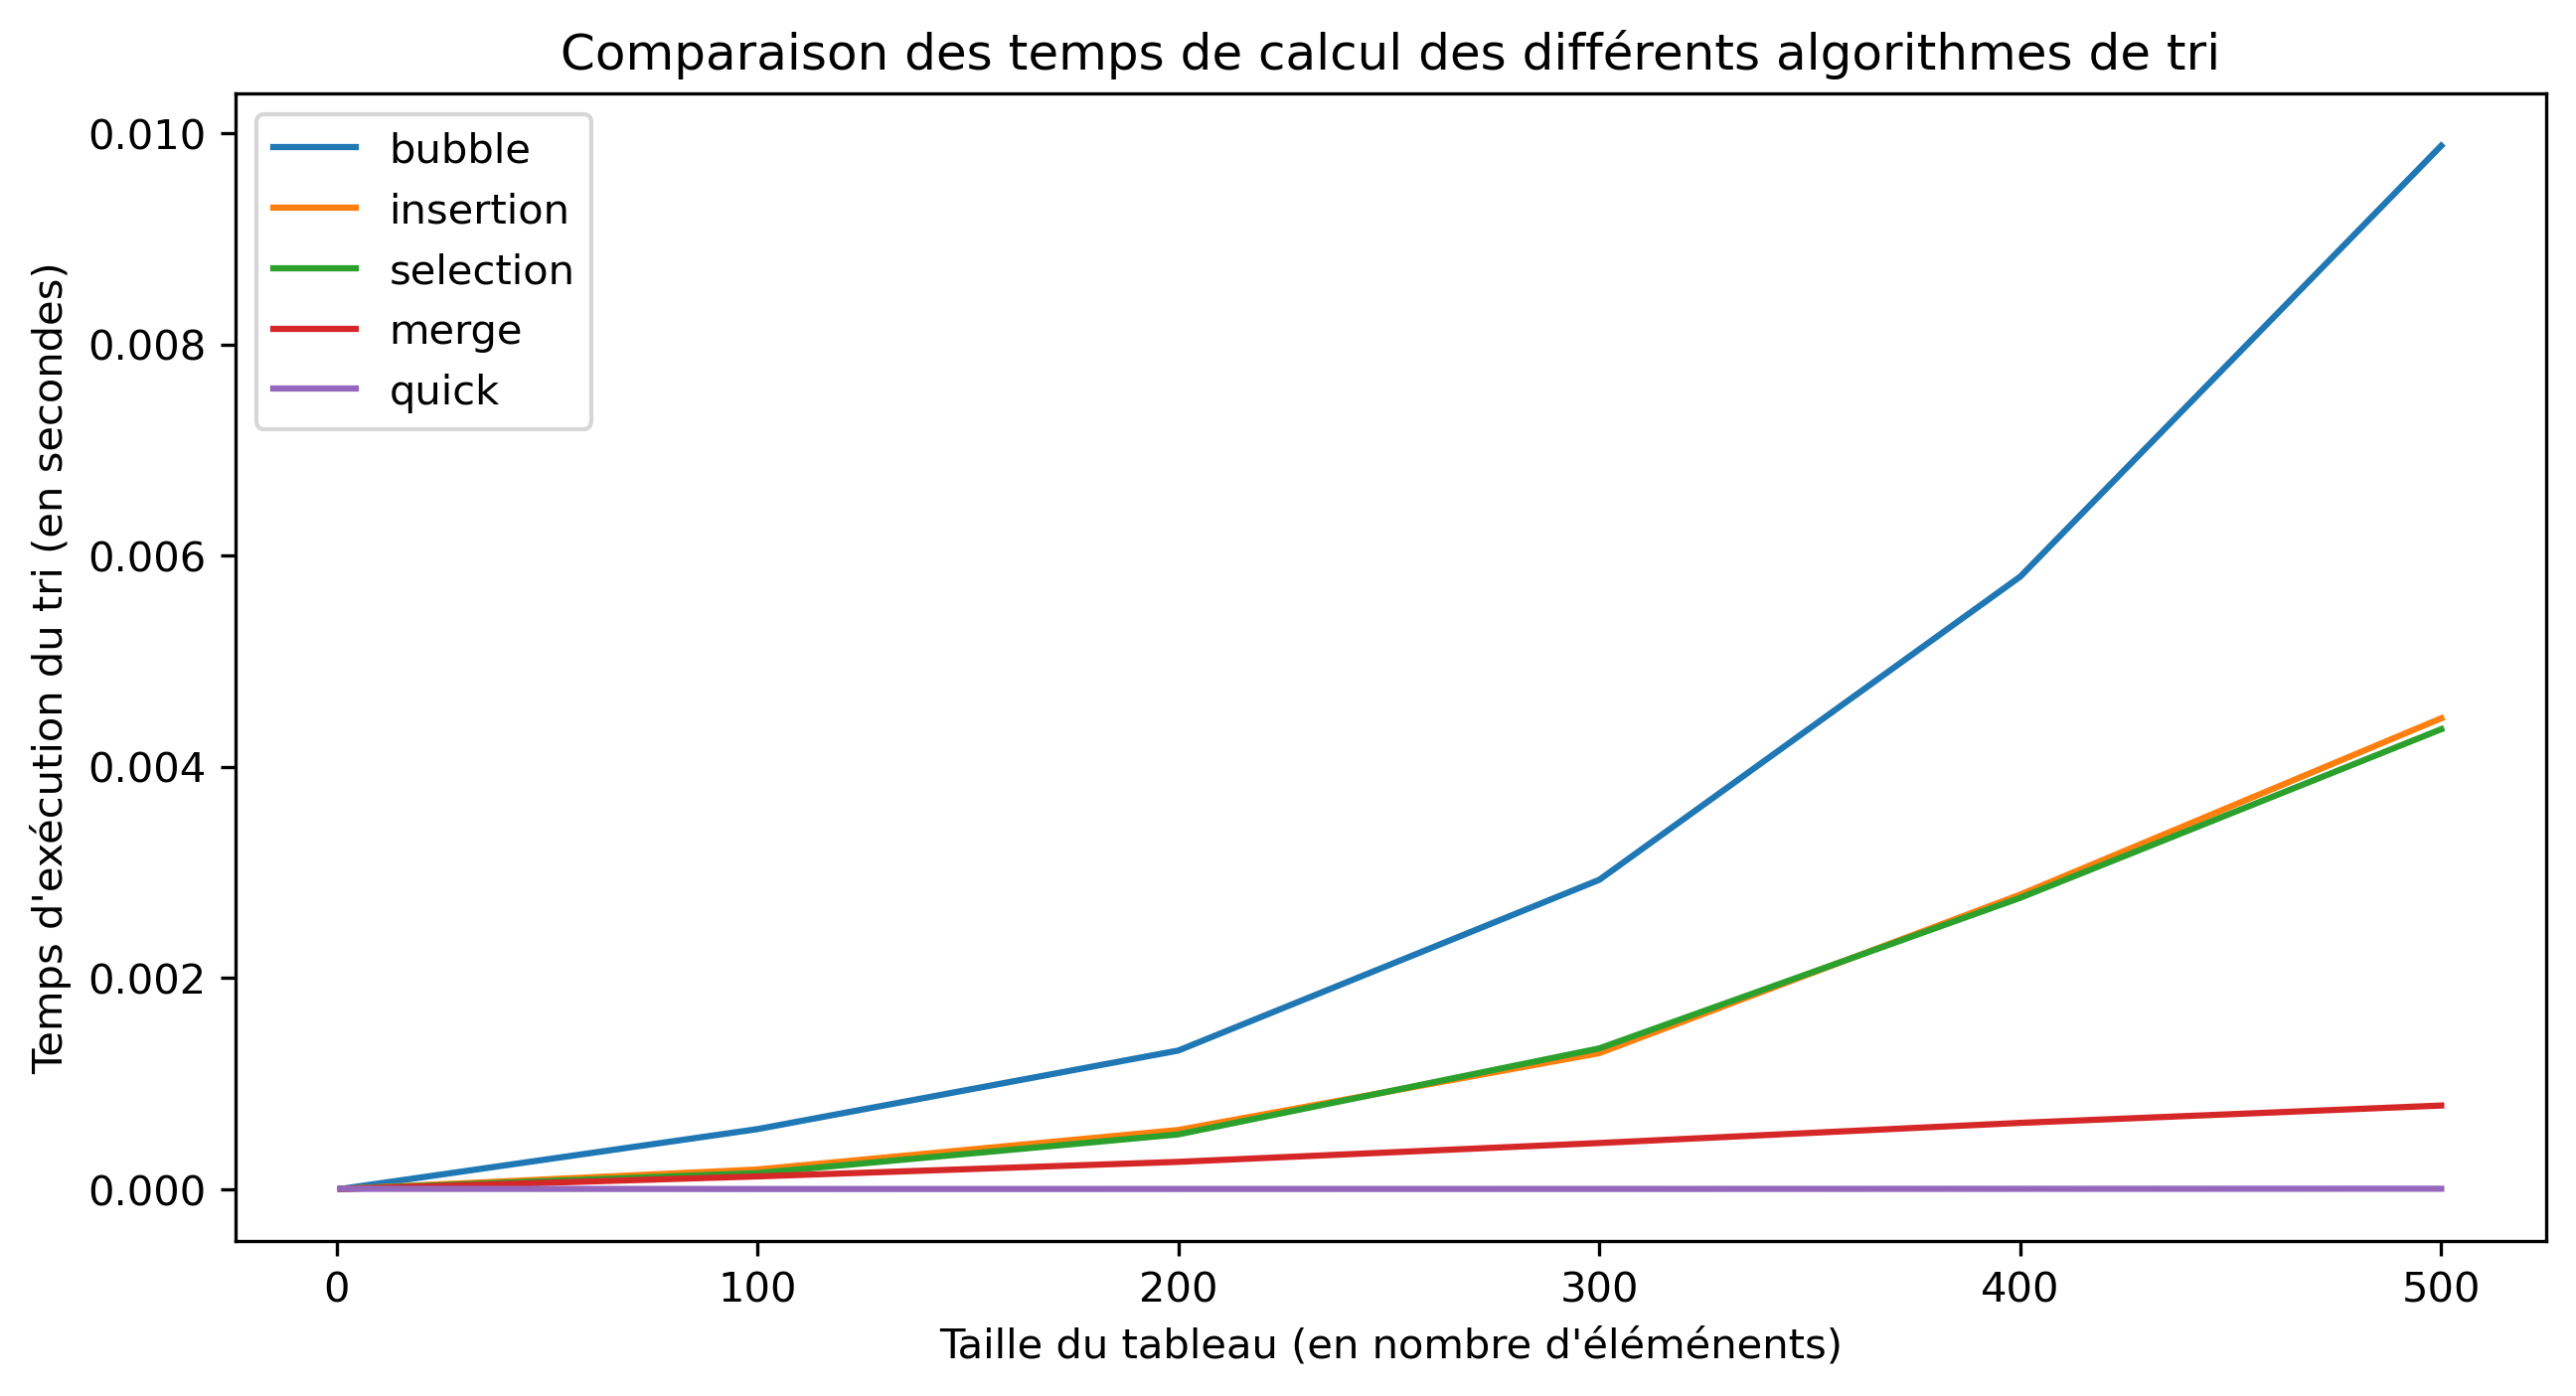

In [33]:
plt.figure(figsize=(10, 5), dpi=300.0)
plt.plot(tailles, bubble, label='bubble')
plt.plot(tailles, insertion, label='insertion')
plt.plot(tailles, selection, label='selection')
plt.plot(tailles, merge, label='merge')
plt.plot(tailles, quick, label='quick')
plt.xlabel("Taille du tableau (en nombre d'éléménents)")
plt.ylabel("Temps d'exécution du tri (en secondes)")
plt.title("Comparaison des temps de calcul des différents algorithmes de tri")
plt.legend();

Cette comparaison pourrait encore être améliorée. Pour chaque taille, il faudrait générer plusieurs tableaux et moyenner les temps obtenus pour tous les tableaux de la même taille. Mais déjà comme ça, il est possible de conclure que le tri rapide est effectivement rapide, comparativement aux autres tris.

## Itération 3 (facultative)

Cette partie était entièrement facultative. Elle servait à occuper les plus rapides d'entre vous en proposant des défis choisis spécialement pour leur difficulté. Je mets des éléments de réponse pour les quelques-uns qui l'ont attaqué. Mais rassurez-vous, personne n'est allé au bout. Ça aurait demandé plus de temps que ce dont vous disposiez.

### Recherches supplémentaires

L'algorithme de tri de Python est [Timsort](https://fr.wikipedia.org/wiki/Timsort). Il s'agit d'un tri hybride, mélangeant le tri par insertion et le tri fusion. C'est un tri [stable](https://fr.wikipedia.org/wiki/Algorithme_de_tri#Tri_stable).

### Programmation dynamique

In [34]:
def fib(n):
    if n <= 1:
        return 1
    else:
        return fib(n - 1) + fib(n - 2)
    
print(
    "Temps de calcul pour Fibonacci récursif :",
    timeit.timeit(globals=globals(), stmt="fib(25)", number=1000) / 1000
)

Temps de calcul pour Fibonacci récursif : 0.01019011552000302


Le calcul de `fib(n)` demande à exécuter le calcul de `fib(n - 1)` et `fib(n - 2)`. Sauf que le calcul de `fib(n - 1)` demande le calcul de `fib(n - 2)` et `fib(n - 3)`. On doit donc calculer deux fois `fib(n - 2)` ! Et comme `fib(n - 2)` demande le calcul de `fib(n - 3)`, on doit calculer trois fois `fib(n - 3)`. Et ainsi de suite. On se retrouve à appeler énormément de fois la fonction avec des paramètres identiques. C'est hautement inefficace, vu qu'on calcule plusieurs fois la même chose. Tous les appels récursifs pourraient se représenter sous la forme d'un énorme arbre :

```
                 f(n)
                 /  \
                /    \
               /      \
              /        \
             /          \ 
            /            \ 
         f(n-1)        f(n-2)
          / \            / \
         /   \          /   \
        /     \        /     \
     f(n-2) f(n-3)  f(n-3) f(n-4)
      /  \    / \    / \    / \
     /    \  [...]  [...]  [...]
 f(n-3) f(n-4) 
   / \     / \
  [...]   [...]
```

In [35]:
from functools import lru_cache

@lru_cache
def fib_cache(n):
    if n <= 1:
        return 1
    else:
        return fib_cache(n - 1) + fib_cache(n - 2)
    
print(
    "Temps de calcul pour Fibonacci récursif avec cache :",
    timeit.timeit(globals=globals(), stmt="fib_cache.cache_clear(); fib_cache(25)", number=1000) / 1000
)

Temps de calcul pour Fibonacci récursif avec cache : 6.739104006555863e-06


[Le décorateur](https://zestedesavoir.com/tutoriels/954/notions-de-python-avancees/2-functions/3-decorators/) `@lru_cache` enregistre dans un dictionnaire le couple arguments de la fonction et valeur de retour. Ainsi, si on a déjà calculé `fib(n - 2)`, on le récupère à partir du dictionnaire plutôt que de le recalculer. Comme on réutilise le résultat de `fib(n - 2)` sans refaire le calcul, pas besoin de recalculer `fib(n - 3)` non plus. En fait, on ne calcule chaque terme de la suite qu'une fois. On passe d'un gros arbre de calcul, à juste $n$ appels récursifs de fonction.

Le temps de calcul parle de lui-même. On économise énormément !

L'arbre des appels récursifs est élagué, il ne reste plus que la première branche à calculer :

```
                 f(n)
                 /  \
                /    \
               /      \
              /        \
             /          \ 
            /            \ 
         f(n-1)        f(n-2)
          / \         en cache   
         /   \
        /     \
     f(n-2) f(n-3)
      /  \ en cache
     /    \
 f(n-3) f(n-4)
   /   en cache
[...]
```

### Calendrier de l'avent


#### Jour 14

Lien vers le défi : [https://adventofcode.com/2021/day/14](https://adventofcode.com/2021/day/14)

Nous avons beaucoup parlé de complexité temporelle. Il existe aussi la notion de complexité spatiale. Et c'est elle qui va poser problème ici, si on code naïvement une solution au problème.

En effet, d'une itération à l'autre, la taille des données double ! En réalité, si la taille de notre chaîne de caractères est $n$, elle sera $2n - 1$ à l'itération d'après. Mais le $-1$ devient vite négligeable... La chaîne de caractères initiale fait 20 caractères. Au bout de 10 itérations (partie 1 du défi), elle fera 20 480 caractères de long. Mais au bout de 40 itérations (partie 2 du défi), elle fera 21 990 232 555 520 caractères. Si on compte un octet par caractère, ça représente quand même **~22 To de RAM**. Waouh ! 

La complexité spatiale de la solution naïve étant trop grande, il faut trouver un autre algorithme. Il ne faut pas agrandir la chaîne à chaque itération.

L'astuce consiste à compter toutes les paires dans un dictionnaire. Chaque paire se transforme en 2 paires à l'itération d'après. On peut donc compter, dans un nouveau dictionnaire, les chaînes présentes à l'itération d'après. On remplace le dictionnaire initial avec le nouveau et on itère jusqu'à avoir le bon nombre d'itérations.

Enﬁn, il faut dénombrer proprement le nombre d'éléments (division par deux car 1 élément est commun à deux paires et ne pas oublier de soustraire 1 exemplaire des éléments en début et ﬁn de chaîne).

N'hésitez pas à chercher les solutions Python dans le [_thread reddit_ des solutions](https://www.reddit.com/r/adventofcode/comments/rfzq6f/2021_day_14_solutions/).


#### Jour 23

Lien vers le défi : [https://adventofcode.com/2021/day/23](https://adventofcode.com/2021/day/23)

L'idée ici est de réfléchir avant de coder. Déjà, en essayant de résoudre le problème à la main, on se rend compte de beaucoup de choses qui simplifie la vision du problème.

La décomposition du problème en sous-problème est très bien expliquée sur cette ressource : [https://www.miximum.fr/blog/aoc-2021-jour-23-amphipodes/](https://www.miximum.fr/blog/aoc-2021-jour-23-amphipodes/).
